# Data Analyst – Customer Churn Exploration

## Project
PerfectPetClub Customer Churn Prediction

## My Responsibilities
- Explore the available datasets.
- Check data quality and missing values.
- Investigate potential features associated with customer churn.
- Collaborate with the Data Engineer and Data Scientist.
- Support model evaluation and visualisation.

In [ ]:
# Step 1: Import the libraries needed for data exploration

import os
import pandas as pd
import sqlite3

print("Libraries imported successfully!")

In [ ]:
# Step 2: Check the project folder and available data files

project_path = os.path.abspath("..")

print("Project folder:", project_path)

raw_data_path = os.path.join(project_path, "data", "raw")

print("\nFiles available in the raw data folder:")

for filename in os.listdir(raw_data_path):
    print("-", filename)

In [ ]:
# Step 3: Load the three CSV files

crm_path = os.path.join(raw_data_path, "PerfectPetClub_CRM_report.csv")
server_path = os.path.join(raw_data_path, "PerfectPetClub_server_log.csv")
survey_path = os.path.join(raw_data_path, "PerfectPetClub_survey.csv")

crm_df = pd.read_csv(crm_path)
server_df = pd.read_csv(server_path)
survey_df = pd.read_csv(survey_path)

print("All three CSV files loaded successfully!")

In [ ]:
# Step 4: Examine dataset sizes and column names

datasets = {
    "CRM Report": crm_df,
    "Server Log": server_df,
    "Survey": survey_df
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])
    print("Column names:", list(df.columns))

In [ ]:
# Step 5: Data quality checks

for name, df in datasets.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:")
    print(df.duplicated().sum())

    print("\nDataset size:")
    print(df.shape)

In [ ]:
# Step 6: Inspect the SQLite database structure

db_path = os.path.join(raw_data_path, "PerfectPetClub.db")

# Connect to the database
connection = sqlite3.connect(db_path)

# Find all tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
    """,
    connection
)

print("Tables found in the database:")
print(tables)

# Inspect the columns in each table
for table_name in tables["name"]:

    print("\n" + "=" * 50)
    print("Table:", table_name)
    print("=" * 50)

    schema = pd.read_sql_query(
        f'PRAGMA table_info("{table_name}")',
        connection
    )

    print(schema[["name", "type"]])

connection.close()

In [ ]:
# Step 7: Investigate subscription information

connection = sqlite3.connect(db_path)

# Count records in the main database tables
table_names = [
    "customer",
    "subscription",
    "subscription_type",
    "sale",
    "payment",
    "product_review"
]

print("RECORD COUNTS")
print("=" * 40)

for table_name in table_names:
    count = pd.read_sql_query(
        f'SELECT COUNT(*) AS total FROM "{table_name}"',
        connection
    )

    print(table_name, ":", count.loc[0, "total"])


# Investigate auto-renew values
print("\nAUTO-RENEW DISTRIBUTION")
print("=" * 40)

auto_renew_summary = pd.read_sql_query(
    """
    SELECT
        auto_renew,
        COUNT(*) AS total_subscriptions
    FROM subscription
    GROUP BY auto_renew
    ORDER BY auto_renew
    """,
    connection
)

print(auto_renew_summary)


# Investigate subscription dates
print("\nSUBSCRIPTION DATE SUMMARY")
print("=" * 40)

date_summary = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total,
        SUM(CASE WHEN start_date IS NULL OR TRIM(start_date) = '' THEN 1 ELSE 0 END) AS missing_start_dates,
        SUM(CASE WHEN end_date IS NULL OR TRIM(end_date) = '' THEN 1 ELSE 0 END) AS missing_end_dates
    FROM subscription
    """,
    connection
)

print(date_summary)

connection.close()

In [ ]:
# Step 8: Investigate subscription dates

connection = sqlite3.connect(db_path)

subscription_dates = pd.read_sql_query(
    """
    SELECT
        auto_renew,
        MIN(start_date) AS earliest_start,
        MAX(start_date) AS latest_start,
        MIN(end_date) AS earliest_end,
        MAX(end_date) AS latest_end,
        COUNT(*) AS total
    FROM subscription
    GROUP BY auto_renew
    ORDER BY auto_renew
    """,
    connection
)

print("SUBSCRIPTION DATE RANGES")
print(subscription_dates)


# Step 9: Investigate delivery performance

delivery_summary = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_sales,
        SUM(CASE
            WHEN delivered_date IS NULL OR TRIM(delivered_date) = ''
            THEN 1 ELSE 0
        END) AS missing_delivery_dates,
        SUM(CASE
            WHEN delivered_date > expected_date
            THEN 1 ELSE 0
        END) AS potentially_late_deliveries
    FROM sale
    """,
    connection
)

print("\nDELIVERY PERFORMANCE")
print(delivery_summary)

connection.close()

In [ ]:
# Step 8: Investigate subscription dates

connection = sqlite3.connect(db_path)

subscription_dates = pd.read_sql_query(
    """
    SELECT
        auto_renew,
        MIN(start_date) AS earliest_start,
        MAX(start_date) AS latest_start,
        MIN(end_date) AS earliest_end,
        MAX(end_date) AS latest_end,
        COUNT(*) AS total
    FROM subscription
    GROUP BY auto_renew
    ORDER BY auto_renew
    """,
    connection
)

print("SUBSCRIPTION DATE RANGES")
print(subscription_dates)


# Step 9: Investigate delivery performance

delivery_summary = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_sales,
        SUM(CASE
            WHEN delivered_date IS NULL OR TRIM(delivered_date) = ''
            THEN 1 ELSE 0
        END) AS missing_delivery_dates,
        SUM(CASE
            WHEN delivered_date > expected_date
            THEN 1 ELSE 0
        END) AS potentially_late_deliveries
    FROM sale
    """,
    connection
)

print("\nDELIVERY PERFORMANCE")
print(delivery_summary)

connection.close()

## Initial Data Exploration Findings

1. Three CSV datasets were identified: CRM, server logs and customer surveys.
2. The SQLite database contains 10 tables, including customer, subscription, sale and product review.
3. The customer and subscription tables each contain 221 records.
4. The subscription table contains 86 records with auto_renew = 0
   and 135 records with auto_renew = 1.
5. No missing values or exact duplicate rows were detected in the
   three CSV datasets.
6. All 221 subscription records have populated start and end dates.

Further investigation is required to confirm the churn definition,
validate date fields and identify useful predictive features.

In [ ]:
# Step 10: Compare auto-renew status with subscription end dates

connection = sqlite3.connect(db_path)

churn_investigation = pd.read_sql_query(
    """
    SELECT
        auto_renew,
        COUNT(*) AS total_subscriptions,

        SUM(
            CASE
                WHEN DATE(end_date) < DATE('now')
                THEN 1 ELSE 0
            END
        ) AS ended_before_today,

        SUM(
            CASE
                WHEN DATE(end_date) >= DATE('now')
                THEN 1 ELSE 0
            END
        ) AS ending_today_or_later

    FROM subscription
    GROUP BY auto_renew
    ORDER BY auto_renew
    """,
    connection
)

print(churn_investigation)

connection.close()

7. Subscription end dates range from January to December 2026.
8. Some subscriptions have future end dates, so auto-renew status
   alone should not automatically be treated as confirmed churn.
9. The sales table contains 23,188 records.
10. There are 1,090 missing delivery dates and 856 potentially
    late deliveries.
11. Further investigation is required to distinguish missing
    delivery information from genuinely late deliveries.

In [ ]:
# Step 11: Check customer-subscription relationships

connection = sqlite3.connect(db_path)

relationship_check = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_customers,

        COUNT(s.id) AS matched_subscriptions,

        COUNT(DISTINCT c.id) AS unique_customers,

        COUNT(DISTINCT s.id) AS unique_subscriptions,

        SUM(
            CASE WHEN s.auto_renew = 0
            THEN 1 ELSE 0 END
        ) AS customers_with_auto_renew_disabled,

        SUM(
            CASE WHEN s.auto_renew = 1
            THEN 1 ELSE 0 END
        ) AS customers_with_auto_renew_enabled

    FROM customer c

    LEFT JOIN subscription s
        ON c.subscription_id = s.id
    """,
    connection
)

print(relationship_check)

connection.close()

12. There are 86 subscriptions with auto_renew disabled
    and 135 with auto_renew enabled.
13. Of the 86 subscriptions with auto-renew disabled,
    80 have end dates before the current date and 6 have
    future end dates.
14. Ten subscriptions with auto-renew enabled also have
    end dates before the current date.
15. The auto_renew field is a potential source of the
    churn target, subject to confirmation of its meaning.
16. Subscription end dates and auto-renew status should
    be investigated separately.

In [ ]:
# Step 12: Check survey-to-customer matching

connection = sqlite3.connect(db_path)

survey_match = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_survey_records,

        COUNT(c.id) AS matched_customers,

        COUNT(DISTINCT s.email) AS unique_survey_emails,

        COUNT(DISTINCT c.id) AS unique_matched_customers

    FROM (
        SELECT LOWER(TRIM(email)) AS email
        FROM customer_survey
    ) s

    LEFT JOIN (
        SELECT id, LOWER(TRIM(email)) AS email
        FROM customer
    ) c
    ON s.email = c.email
    """,
    connection
)

print(survey_match)

connection.close()

In [ ]:
# Step 12: Match survey emails to customer emails

connection = sqlite3.connect(db_path)

survey_df.to_sql(
    "temporary_survey",
    connection,
    if_exists="replace",
    index=False
)

survey_match = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_survey_records,
        COUNT(c.id) AS matched_customers,
        COUNT(DISTINCT s.email) AS unique_survey_emails,
        COUNT(DISTINCT c.id) AS unique_matched_customers

    FROM temporary_survey s

    LEFT JOIN customer c
      ON LOWER(TRIM(s.email)) = LOWER(TRIM(c.email))
    """,
    connection
)

print(survey_match)

connection.close()

17. All 221 customers have a matching subscription.
18. The customer-subscription relationship is one-to-one
    in the current database.
19. Survey-to-customer matching is being investigated
    using email addresses without displaying personal information.

In [ ]:
# Step 13: Check CRM-to-customer matching

connection = sqlite3.connect(db_path)

crm_df.to_sql(
    "temporary_crm",
    connection,
    if_exists="replace",
    index=False
)

crm_match = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_crm_records,
        COUNT(c.id) AS matched_crm_records,
        COUNT(DISTINCT r.customer_id) AS unique_crm_customers,
        COUNT(DISTINCT c.id) AS unique_matched_customers

    FROM temporary_crm r

    LEFT JOIN customer c
        ON r.customer_id = c.id
    """,
    connection
)

print("CRM CUSTOMER MATCHING")
print(crm_match)

# Investigate CRM event types
print("\nCRM EVENT TYPES")

crm_events = pd.read_sql_query(
    """
    SELECT
        type,
        COUNT(*) AS total_events
    FROM temporary_crm
    GROUP BY type
    ORDER BY total_events DESC
    """,
    connection
)

print(crm_events)

connection.close()

## Customer and Survey Data Integration

20. All 221 survey records matched customer records using
    normalised email addresses.
21. The survey contains 221 unique email addresses.
22. The customer and subscription tables have a complete
    one-to-one relationship.
23. CRM-to-customer matching is being investigated using
    customer IDs.

In [ ]:
# Clean up the two helper tables created during analysis

connection = sqlite3.connect(db_path)

connection.execute("DROP TABLE IF EXISTS temporary_crm")
connection.execute("DROP TABLE IF EXISTS temporary_survey")

connection.commit()
connection.close()

print("Helper tables removed. Original project tables preserved.")

In [ ]:
# Step 14: Analyse CRM events by customer

crm_customer_summary = (
    crm_df.groupby(["customer_id", "type"])
    .size()
    .unstack(fill_value=0)
)

# Make sure both event categories are represented
for event in ["complaint", "query"]:
    if event not in crm_customer_summary.columns:
        crm_customer_summary[event] = 0

print("CRM CUSTOMER EVENT SUMMARY")
print("Number of customers:", len(crm_customer_summary))

print("\nComplaint statistics:")
print(crm_customer_summary["complaint"].describe())

print("\nQuery statistics:")
print(crm_customer_summary["query"].describe())

print("\nCustomers with no CRM events:", 221 - len(crm_customer_summary))

## CRM Customer Behaviour Analysis

24. All 7,585 CRM records matched customer IDs.
25. CRM activity was recorded for 200 of the 221 customers.
26. The CRM report contains 3,837 complaints and 3,748 queries.
27. Average complaints per customer: 19.19.
28. Average queries per customer: 18.74.
29. The median complaint count was 9.5 and the median query
    count was 9.
30. Complaint count, query count and total CRM events are
    potential features for churn prediction.
31. Twenty-one customers had no CRM events.
32. Further analysis is required to determine whether CRM
    activity is associated with customer churn.

In [ ]:
# Step 15: Investigate server login activity

print("SERVER LOG OVERVIEW")
print("Total records:", len(server_df))
print("Unique sessions:", server_df["session_id"].nunique())
print("Unique login values:", server_df["login"].nunique())

print("\nLOGIN VALUE FREQUENCIES")
print(server_df["login"].value_counts(dropna=False))

print("\nDATE RANGE")

server_dates = pd.to_datetime(
    server_df["datetime"],
    errors="coerce"
)

print("Earliest date:", server_dates.min())
print("Latest date:", server_dates.max())
print("Invalid dates:", server_dates.isna().sum())

In [ ]:
# Step 16: Analyse login activity by customer

# Count login records for each customer internally
login_counts = (
    server_df.groupby("login")
    .size()
)

print("CUSTOMER LOGIN ACTIVITY")
print("=" * 40)

print("Number of customers:", login_counts.count())

print("\nLogin count statistics:")
print(login_counts.describe())

print("\nCustomers with fewer than 10 logins:",
      (login_counts < 10).sum())

print("Customers with more than 100 logins:",
      (login_counts > 100).sum())

print("\nTotal login records:", login_counts.sum())

## Server Login Activity Analysis

33. The server log contains 67,249 records.
34. All 67,249 session IDs are unique.
35. Login activity was recorded for 221 unique customers.
36. All server timestamps were successfully parsed.
37. Server activity ranges from 1 January 2026 to
    10 November 2026.
38. Login count per customer is a potential feature
    for customer churn prediction.
39. Further investigation is required to establish
    whether login activity is associated with churn.

## Customer Login Activity Findings

40. Login activity was recorded for all 221 customers.

41. The server log contains 67,249 total login records.

42. The average number of logins per customer is approximately 304.

43. The median number of logins per customer is 198.

44. Login activity varies considerably, ranging from 1 to 1,540
    records per customer.

45. Five customers had fewer than 10 login records.

46. A total of 159 customers had more than 100 login records.

47. Login count may be a useful feature for customer churn prediction.

48. Further analysis is required to determine whether lower login
    activity is associated with churn.

In [ ]:
# Step 17: Analyse how recently customers logged in

server_analysis = server_df.copy()

# Convert the server timestamps into datetime format
server_analysis["datetime_parsed"] = pd.to_datetime(
    server_analysis["datetime"],
    errors="coerce"
)

# Calculate login activity for each customer
login_features = (
    server_analysis.groupby("login")
    .agg(
        login_count=("session_id", "count"),
        first_login=("datetime_parsed", "min"),
        last_login=("datetime_parsed", "max")
    )
)

# Use the latest date in the dataset as the reference date
reference_date = server_analysis["datetime_parsed"].max()

# Calculate days since each customer's last recorded login
login_features["days_since_last_login"] = (
    reference_date - login_features["last_login"]
).dt.days

print("LOGIN RECENCY ANALYSIS")
print("=" * 40)

print("\nDays since last login:")
print(login_features["days_since_last_login"].describe())

print(
    "\nCustomers with no login in the last 7 days:",
    (login_features["days_since_last_login"] > 7).sum()
)

print(
    "Customers with no login in the last 30 days:",
    (login_features["days_since_last_login"] > 30).sum()
)

print("\nCustomers analysed:", len(login_features))

## Login Frequency and Recency Analysis

40. Login activity was recorded for 221 customers.

41. Customers generated 67,249 total login records.

42. The average number of logins per customer was approximately 304.29.

43. The median number of logins per customer was 198.

44. Five customers had fewer than 10 logins, while 159
    customers had more than 100 logins.

45. The average time since the last login was approximately
    58 days, while the median was only 1 day.

46. A total of 81 customers had not logged in during the
    previous 7 days.

47. A total of 72 customers had not logged in during the
    previous 30 days.

48. Login frequency and days since last login are potential
    features for customer churn prediction.

49. Further analysis is required to determine whether
    reduced login activity is associated with churn.

## Feature Analysis – CRM Activity and Subscription Status

This analysis investigates whether customer complaint and query activity differs between the two auto-renew groups. The auto_renew column is treated as a candidate target pending confirmation from the Data Engineer.

In [1]:
import os
import sqlite3
import pandas as pd

# Locate the project files
project_path = os.path.abspath("..")
crm_path = os.path.join(
    project_path, "data", "raw", "PerfectPetClub_CRM_report.csv"
)
db_path = os.path.join(
    project_path, "data", "raw", "PerfectPetClub.db"
)

# Load CRM activity
crm_analysis = pd.read_csv(crm_path)

# Load customer subscription status
connection = sqlite3.connect(db_path)

customer_status = pd.read_sql_query("""
    SELECT
        c.id AS customer_id,
        s.auto_renew
    FROM customer c
    JOIN subscription s
        ON c.subscription_id = s.id
""", connection)

connection.close()

# Count CRM complaints and queries per customer
crm_analysis["type"] = (
    crm_analysis["type"].astype(str).str.strip().str.lower()
)

crm_features = (
    crm_analysis
    .groupby(["customer_id", "type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Rename the activity columns
crm_features = crm_features.rename(columns={
    "complaint": "complaint_count",
    "query": "query_count"
})

# Ensure both feature columns exist
for column in ["complaint_count", "query_count"]:
    if column not in crm_features.columns:
        crm_features[column] = 0

# Calculate total CRM activity
crm_features["total_crm_events"] = (
    crm_features["complaint_count"] +
    crm_features["query_count"]
)

# Combine CRM features with subscription status
feature_analysis = customer_status.merge(
    crm_features,
    on="customer_id",
    how="left"
)

# Customers without CRM activity receive zero counts
activity_columns = [
    "complaint_count",
    "query_count",
    "total_crm_events"
]

feature_analysis[activity_columns] = (
    feature_analysis[activity_columns].fillna(0)
)

# Compare activity across auto-renew groups
crm_comparison = (
    feature_analysis
    .groupby("auto_renew")
    .agg(
        customers=("customer_id", "nunique"),
        average_complaints=("complaint_count", "mean"),
        average_queries=("query_count", "mean"),
        average_total_events=("total_crm_events", "mean"),
        median_total_events=("total_crm_events", "median")
    )
    .round(2)
)

print("CRM ACTIVITY BY AUTO-RENEW GROUP")
display(crm_comparison)

print("Total customers analysed:", feature_analysis["customer_id"].nunique())
print("Total CRM events:", int(feature_analysis["total_crm_events"].sum()))

CRM ACTIVITY BY AUTO-RENEW GROUP


,customers,average_complaints,average_queries,average_total_events,median_total_events
auto_renew,,,,,
0,86,12.15,12.10,24.26,12.0
1,135,20.68,20.05,40.73,19.0


Total customers analysed: 221
Total CRM events: 7585


### Findings – CRM Activity and Subscription Status

- The analysis included all 221 customers.
- Customers with auto_renew = 1 had a higher average number of complaints (20.68) than customers with auto_renew = 0 (12.15).
- Customers with auto_renew = 1 also had a higher average number of queries (20.05 compared with 12.10).
- Average total CRM activity was 40.73 events for auto_renew = 1 and 24.26 events for auto_renew = 0.
- These results show an association between CRM activity and subscription status in this dataset. They do not establish causation.
- The meaning of the auto_renew target still needs confirmation from the Data Engineer.

### Feature Correlation Analysis

This analysis investigates the relationship between CRM activity features and the candidate auto-renew target using Pearson and Spearman correlations.

PEARSON CORRELATION WITH AUTO_RENEW


,auto_renew
complaint_count,0.183
total_crm_events,0.178
query_count,0.170


SPEARMAN CORRELATION WITH AUTO_RENEW


,auto_renew
complaint_count,0.143
query_count,0.140
total_crm_events,0.139


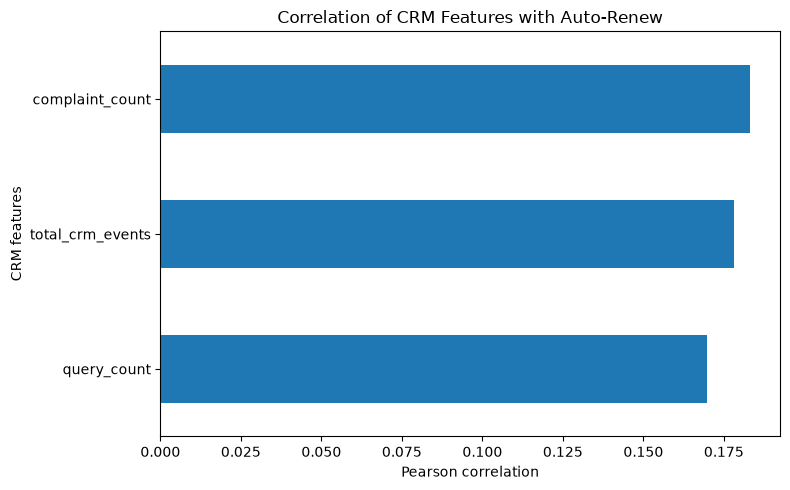

In [2]:
import matplotlib.pyplot as plt

# Select features for correlation analysis
correlation_features = [
    "auto_renew",
    "complaint_count",
    "query_count",
    "total_crm_events"
]

correlation_data = feature_analysis[correlation_features]

# Pearson correlation
pearson_corr = correlation_data.corr(method="pearson")

print("PEARSON CORRELATION WITH AUTO_RENEW")
display(
    pearson_corr[["auto_renew"]]
    .drop(index="auto_renew")
    .sort_values("auto_renew", ascending=False)
    .round(3)
)

# Spearman correlation
spearman_corr = correlation_data.corr(method="spearman")

print("SPEARMAN CORRELATION WITH AUTO_RENEW")
display(
    spearman_corr[["auto_renew"]]
    .drop(index="auto_renew")
    .sort_values("auto_renew", ascending=False)
    .round(3)
)

# Visualise Pearson correlations
pearson_values = (
    pearson_corr["auto_renew"]
    .drop("auto_renew")
    .sort_values()
)

plt.figure(figsize=(8, 5))
pearson_values.plot(kind="barh")
plt.title("Correlation of CRM Features with Auto-Renew")
plt.xlabel("Pearson correlation")
plt.ylabel("CRM features")
plt.tight_layout()
plt.show()

### Findings – Feature Correlation Analysis

- Pearson and Spearman correlation methods both showed weak positive relationships between CRM activity features and auto_renew.
- Complaint count had the strongest correlation with auto_renew (Pearson: 0.183; Spearman: 0.143).
- Query count showed a weak positive correlation (Pearson: 0.170; Spearman: 0.140).
- Total CRM events also showed a weak positive correlation (Pearson: 0.178; Spearman: 0.139).
- Complaint count may be worth investigating further as a potential predictive feature.
- Total CRM events overlaps with complaint and query counts because it is calculated from these two features.
- Correlation does not establish causation or prove predictive usefulness.
- The meaning of auto_renew as the churn target requires confirmation from the Data Engineer.

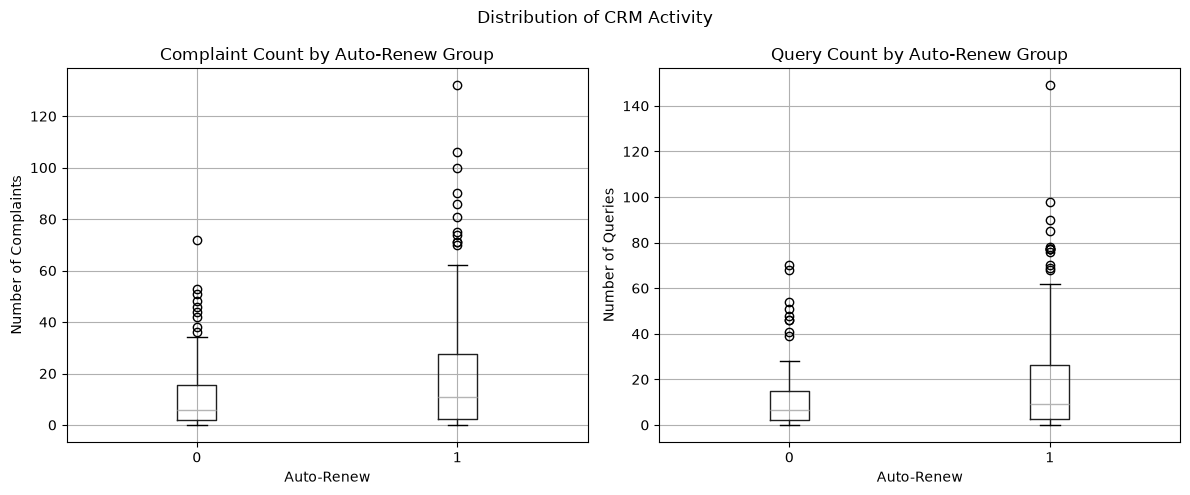

In [3]:
import matplotlib.pyplot as plt

# Compare complaint and query distributions by auto-renew group
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

feature_analysis.boxplot(
    column="complaint_count",
    by="auto_renew",
    ax=axes[0]
)
axes[0].set_title("Complaint Count by Auto-Renew Group")
axes[0].set_xlabel("Auto-Renew")
axes[0].set_ylabel("Number of Complaints")

feature_analysis.boxplot(
    column="query_count",
    by="auto_renew",
    ax=axes[1]
)
axes[1].set_title("Query Count by Auto-Renew Group")
axes[1].set_xlabel("Auto-Renew")
axes[1].set_ylabel("Number of Queries")

plt.suptitle("Distribution of CRM Activity")
plt.tight_layout()
plt.show()

### Findings – Distribution of CRM Activity

- Boxplots show that the auto_renew = 1 group has higher median complaint and query counts than the auto_renew = 0 group.
- The auto_renew = 1 group also shows greater variation in CRM activity.
- Both groups contain unusually high complaint and query counts.
- The distributions overlap, meaning CRM activity alone may not clearly distinguish the two subscription groups.
- These unusually high observations should be investigated rather than automatically removed, as they may represent genuine customer behaviour.
- The visual findings are consistent with the weak positive correlations identified earlier.

In [5]:
# Calculate potential outliers using the IQR method

for feature in ["complaint_count", "query_count"]:
    print(f"\n{feature.upper()}")

    for group in sorted(feature_analysis["auto_renew"].unique()):
        values = feature_analysis.loc[
            feature_analysis["auto_renew"] == group, feature
        ]

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outliers = values[
            (values < lower_limit) | (values > upper_limit)
        ]

        print(f"Auto-renew group {group}:")
        print("  Customers:", len(values))
        print("  Potential outliers:", len(outliers))
        print("  Upper IQR limit:", round(upper_limit, 2))


COMPLAINT_COUNT
Auto-renew group 0:
  Customers: 86
  Potential outliers: 9
  Upper IQR limit: 35.75
Auto-renew group 1:
  Customers: 135
  Potential outliers: 11
  Upper IQR limit: 65.0

QUERY_COUNT
Auto-renew group 0:
  Customers: 86
  Potential outliers: 9
  Upper IQR limit: 33.88
Auto-renew group 1:
  Customers: 135
  Potential outliers: 13
  Upper IQR limit: 62.5


### Findings – CRM Outlier Analysis

- The IQR method was used to identify potential outliers in complaint and query counts separately for each auto-renew group.
- Complaint count: 9 potential outliers were identified in group 0 (10.5%) and 11 in group 1 (8.1%).
- Query count: 9 potential outliers were identified in group 0 (10.5%) and 13 in group 1 (9.6%).
- Both subscription groups contain customers with unusually high CRM activity.
- The outliers may represent genuine customer behaviour and should not automatically be removed.
- Further investigation is required before deciding whether any preprocessing is necessary.

## Feature Analysis – Customer Login Behaviour

This analysis investigates whether login frequency and login recency differ between the two auto-renew groups.

In [7]:
# Prepare customer subscription status
import sqlite3
import os
import pandas as pd

db_path = os.path.join(
    os.path.abspath(".."),
    "data",
    "raw",
    "PerfectPetClub.db"
)

connection = sqlite3.connect(db_path)

customer_status = pd.read_sql_query("""
    SELECT
        c.id AS customer_id,
        LOWER(TRIM(c.email)) AS login_key,
        s.auto_renew
    FROM customer c
    JOIN subscription s
        ON c.subscription_id = s.id
""", connection)

connection.close()

# Prepare login activity without displaying customer identifiers
# Load server log directly from the project data folder
server_path = os.path.join(
    os.path.abspath(".."),
    "data",
    "raw",
    "PerfectPetClub_server_log.csv"
)

login_data = pd.read_csv(server_path)

login_data["login_key"] = (
    login_data["login"].astype(str).str.strip().str.lower()
)

login_data["login_datetime"] = pd.to_datetime(
    login_data["datetime"], errors="coerce"
)

# Calculate login frequency and last login
login_features = (
    login_data.groupby("login_key")
    .agg(
        login_count=("session_id", "count"),
        last_login=("login_datetime", "max")
    )
    .reset_index()
)

# Combine login activity with subscription status
login_comparison_df = customer_status.merge(
    login_features,
    on="login_key",
    how="left"
)

# Calculate days since last recorded login
reference_date = login_data["login_datetime"].max()

login_comparison_df["days_since_last_login"] = (
    reference_date - login_comparison_df["last_login"]
).dt.days

# Compare the groups
login_comparison = (
    login_comparison_df
    .groupby("auto_renew")
    .agg(
        customers=("customer_id", "nunique"),
        average_logins=("login_count", "mean"),
        median_logins=("login_count", "median"),
        average_days_since_login=("days_since_last_login", "mean"),
        median_days_since_login=("days_since_last_login", "median")
    )
    .round(2)
)

print("LOGIN BEHAVIOUR BY AUTO-RENEW GROUP")
display(login_comparison)

print("Total customers analysed:",
      login_comparison_df["customer_id"].nunique())

print("Reference date:", reference_date)

LOGIN BEHAVIOUR BY AUTO-RENEW GROUP


,customers,average_logins,median_logins,average_days_since_login,median_days_since_login
auto_renew,,,,,
0,86,231.37,165.5,148.22,133.0
1,135,350.75,249.0,0.46,0.0


Total customers analysed: 221
Reference date: 2026-11-10 17:29:19.510000


### Findings – Customer Login Behaviour

- The analysis included all 221 customers.
- Customers with auto_renew = 1 had a higher average login count (350.75) than customers with auto_renew = 0 (231.37).
- The median login count was also higher for auto_renew = 1 (249 compared with 165.5).
- Average days since last login was 148.22 days for auto_renew = 0, compared with 0.46 days for auto_renew = 1.
- The median days since last login was 133 days for auto_renew = 0 and 0 days for auto_renew = 1.
- Login recency appears to show a substantial difference between the two subscription groups and may be a useful predictive feature.
- The reference date was 10 November 2026, based on the latest timestamp in the server log.
- Further investigation is required to check observation-period differences and confirm the meaning of auto_renew before drawing conclusions about churn.

PEARSON CORRELATION WITH AUTO_RENEW


,auto_renew
login_count,0.201
days_since_last_login,-0.752


SPEARMAN CORRELATION WITH AUTO_RENEW


,auto_renew
login_count,0.166
days_since_last_login,-0.881


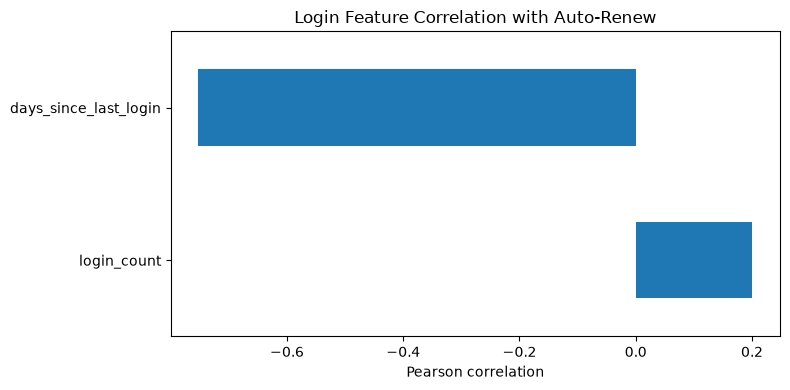

In [8]:
# Select login features and candidate target
login_correlation_data = login_comparison_df[
    [
        "auto_renew",
        "login_count",
        "days_since_last_login"
    ]
].copy()

# Pearson correlation
login_pearson = login_correlation_data.corr(method="pearson")

print("PEARSON CORRELATION WITH AUTO_RENEW")

display(
    login_pearson[["auto_renew"]]
    .drop(index="auto_renew")
    .round(3)
)

# Spearman correlation
login_spearman = login_correlation_data.corr(method="spearman")

print("SPEARMAN CORRELATION WITH AUTO_RENEW")

display(
    login_spearman[["auto_renew"]]
    .drop(index="auto_renew")
    .round(3)
)

# Plot Pearson correlations
login_values = (
    login_pearson["auto_renew"]
    .drop("auto_renew")
)

login_values.plot(
    kind="barh",
    figsize=(8, 4),
    title="Login Feature Correlation with Auto-Renew",
    xlabel="Pearson correlation"
)

plt.tight_layout()
plt.show()

### Findings – Login Feature Correlation Analysis

- Login count showed a weak positive correlation with auto_renew (Pearson: 0.201; Spearman: 0.166).
- Days since last login showed a strong negative Pearson correlation (-0.752).
- Spearman correlation for days since last login was -0.881, indicating a very strong negative rank relationship.
- Customers with more recent login activity tended to have higher auto_renew values.
- Login recency showed a substantially stronger relationship with auto_renew than the CRM activity features investigated earlier.
- Days since last login appears to be a promising candidate feature for further investigation.
- These correlations do not establish causation or prove model performance.
- The prediction date and target definition must be confirmed to prevent data leakage and ensure correct interpretation.

## Combined Feature Analysis

This section combines CRM activity and customer login behaviour to compare their relationships with the candidate auto-renew target.

Combined customer records: 221
Missing values:
 customer_id              0
auto_renew               0
complaint_count          0
query_count              0
total_crm_events         0
login_count              0
days_since_last_login    0
dtype: int64

PEARSON CORRELATION WITH AUTO_RENEW


,auto_renew
login_count,0.201
complaint_count,0.183
total_crm_events,0.178
query_count,0.170
days_since_last_login,-0.752


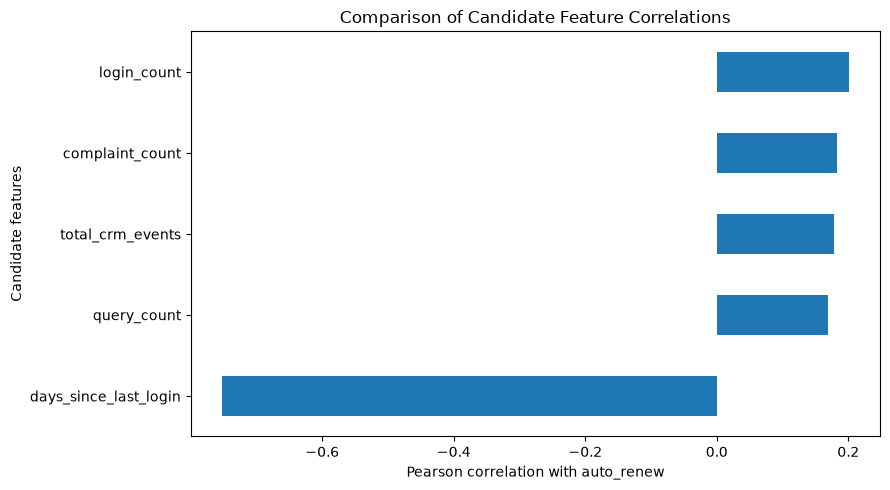

In [9]:
# Combine CRM and login features using customer ID
combined_features = feature_analysis[
    [
        "customer_id",
        "auto_renew",
        "complaint_count",
        "query_count",
        "total_crm_events"
    ]
].merge(
    login_comparison_df[
        [
            "customer_id",
            "login_count",
            "days_since_last_login"
        ]
    ],
    on="customer_id",
    how="inner"
)

# Check dataset completeness
print("Combined customer records:", len(combined_features))
print(
    "Missing values:\n",
    combined_features.isnull().sum()
)

# Calculate Pearson correlations
combined_pearson = combined_features[
    [
        "auto_renew",
        "complaint_count",
        "query_count",
        "total_crm_events",
        "login_count",
        "days_since_last_login"
    ]
].corr(method="pearson")

print("\nPEARSON CORRELATION WITH AUTO_RENEW")

display(
    combined_pearson[["auto_renew"]]
    .drop(index="auto_renew")
    .sort_values("auto_renew", ascending=False)
    .round(3)
)

# Plot feature correlations
combined_corr = (
    combined_pearson["auto_renew"]
    .drop("auto_renew")
    .sort_values()
)

plt.figure(figsize=(9, 5))
combined_corr.plot(kind="barh")
plt.title("Comparison of Candidate Feature Correlations")
plt.xlabel("Pearson correlation with auto_renew")
plt.ylabel("Candidate features")
plt.tight_layout()
plt.show()

### Findings – Combined Feature Correlation Analysis

- Login count showed a weak positive Pearson correlation with auto_renew (0.201).
- Complaint count showed a weak positive correlation (0.183).
- Total CRM events showed a weak positive correlation (0.178).
- Query count showed a weak positive correlation (0.170).
- Days since last login showed the strongest relationship, with a negative Pearson correlation of -0.752.
- Login recency appears to be a promising candidate predictive feature compared with the CRM activity features investigated.
- The results are exploratory and do not establish causation or actual model predictive performance.
- The candidate target definition and prediction date must be confirmed before final feature selection.
- Total CRM events overlaps with complaint and query counts and should not automatically be treated as an independent feature.